# Supervised Learning Model Design and Evaluation (Healthcare: Breast Cancer Diagnosis)

**Subject:** Machine Learning (METCE11504) &nbsp;|&nbsp; **Activity:** ALA 1  
**Student:** ____________________ &nbsp; **Enrollment No.:** ____________

## 1. Problem and dataset
**Problem:** predict whether a breast tumour is **malignant** or **benign** from measurements of cell nuclei (a healthcare classification task).  
**Dataset:** *Wisconsin Diagnostic Breast Cancer* (UCI repository; shipped with scikit-learn): **569 patients, 30 numeric features** (mean, standard error and "worst" value of 10 properties such as radius, texture, perimeter, area, concavity), computed from digitised images of fine-needle aspirates.  
**Positive class = malignant**, because missing a malignant tumour (false negative) is the costly error, so **recall** is especially important.

**Part B (regression, to cover Linear Regression and RMSE):** *Diabetes* dataset (442 patients, 10 baseline variables, target = disease progression after one year).

**Method:** exploration → preprocessing (scaling, feature selection) → model training with hyper-parameter tuning → evaluation (accuracy, precision, recall, F1, ROC-AUC, confusion matrix; RMSE, MAE, R² for regression) → observations.

## 2. Load and explore the data

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, mean_squared_error, mean_absolute_error, r2_score)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
RS = 42

In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data
y = (data.target == 0).astype(int)          # 1 = malignant (positive class), 0 = benign
print("Instances:", X.shape[0], "| Features:", X.shape[1])
print("Missing values:", int(X.isna().sum().sum()))
print("Malignant:", int(y.sum()), f"({y.mean():.1%})  Benign:", int((1 - y).sum()), f"({1 - y.mean():.1%})")
X.iloc[:, :6].describe().round(2)

Instances: 569 | Features: 30
Missing values: 0
Malignant: 212 (37.3%)  Benign: 357 (62.7%)


       mean radius  mean texture  mean perimeter  mean area  mean smoothness  mean compactness
count       569.00        569.00          569.00     569.00           569.00            569.00
mean         14.13         19.29           91.97     654.89             0.10              0.10
std           3.52          4.30           24.30     351.91             0.01              0.05
min           6.98          9.71           43.79     143.50             0.05              0.02
25%          11.70         16.17           75.17     420.30             0.09              0.06
50%          13.37         18.84           86.24     551.10             0.10              0.09
75%          15.78         21.80          104.10     782.70             0.11              0.13
max          28.11         39.28          188.50    2501.00             0.16              0.35

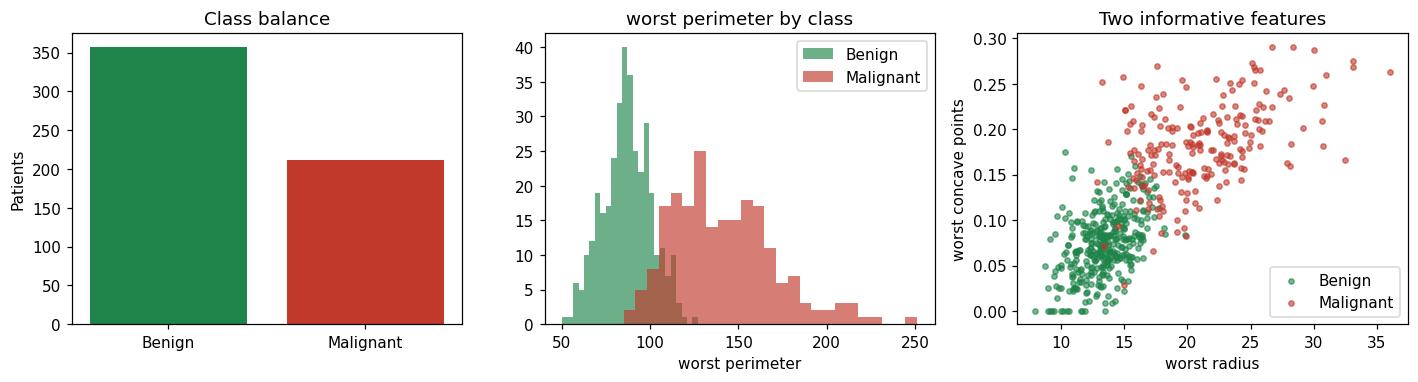

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].bar(["Benign", "Malignant"], [int((1 - y).sum()), int(y.sum())], color=["#1E8449", "#C0392B"]); ax[0].set_title("Class balance"); ax[0].set_ylabel("Patients")
for lab, col, name in ((0, "#1E8449", "Benign"), (1, "#C0392B", "Malignant")):
    ax[1].hist(X.loc[y == lab, "worst perimeter"], bins=25, alpha=.65, color=col, label=name)
    ax[2].scatter(X.loc[y == lab, "worst radius"], X.loc[y == lab, "worst concave points"], s=12, alpha=.6, color=col, label=name)
ax[1].set_title("worst perimeter by class"); ax[1].set_xlabel("worst perimeter"); ax[1].legend()
ax[2].set_title("Two informative features"); ax[2].set_xlabel("worst radius"); ax[2].set_ylabel("worst concave points"); ax[2].legend()
plt.tight_layout()

## 3. Preprocessing: train/test split, scaling and feature selection

In [4]:
# Stratified split keeps the class ratio; the test set is NOT used for any tuning decision.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print("Train:", X_train.shape, "Test:", X_test.shape, "| malignant share train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))
# Scaling is done inside a Pipeline so that the scaler is learned ONLY from the training folds (no data leakage).

Train: (455, 30) Test: (114, 30) | malignant share train/test: 0.374 0.368


In [5]:
# Feature selection with the ANOVA F-score (univariate), computed on the training data only
sel = SelectKBest(f_classif, k="all").fit(StandardScaler().fit_transform(X_train), y_train)
scores = pd.Series(sel.scores_, index=X.columns).sort_values(ascending=False)
print("Top 10 features by F-score:"); print(scores.head(10).round(1).to_string())

Top 10 features by F-score:
worst concave points    733.7
worst perimeter         717.2
worst radius            692.9
mean concave points     684.5
mean perimeter          548.4
worst area              522.2
mean radius             511.3
mean area               444.9
mean concavity          397.6
worst concavity         319.5


In [6]:
# Effect of the number of selected features (5-fold CV accuracy on the training set)
cv5 = StratifiedKFold(5, shuffle=True, random_state=RS)
rows = []
for k in (3, 5, 10, 15, 20, 30):
    for name, clf in (("Logistic Regression", LogisticRegression(max_iter=2000)), ("SVM (RBF)", SVC())):
        pipe = Pipeline([("sc", StandardScaler()), ("sel", SelectKBest(f_classif, k=k)), ("clf", clf)])
        rows.append([k, name, cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="accuracy").mean()])
fs = pd.DataFrame(rows, columns=["k_features", "model", "cv_accuracy"]).pivot(index="k_features", columns="model", values="cv_accuracy").round(4)
fs

model       Logistic Regression  SVM (RBF)
k_features                                
3                        0.9451     0.9473
5                        0.9429     0.9495
10                       0.9538     0.9495
15                       0.9429     0.9429
20                       0.9692     0.9670
30                       0.9736     0.9714

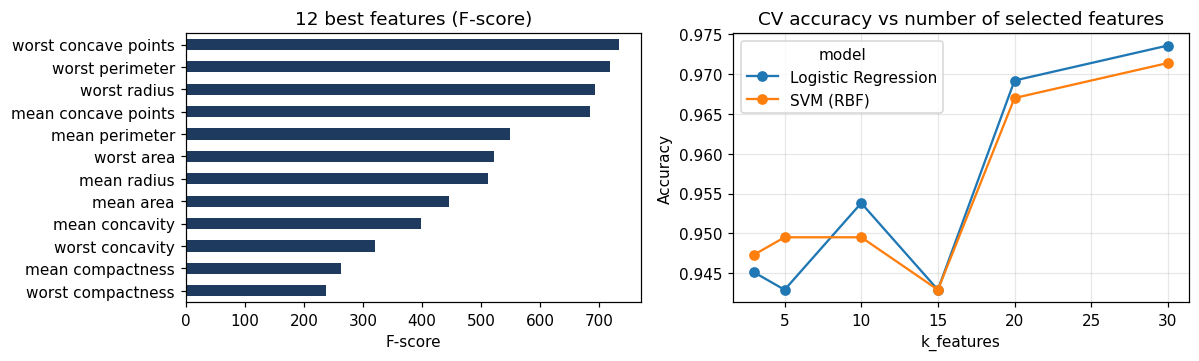

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
scores.head(12).iloc[::-1].plot.barh(ax=ax[0], color="#1F3A5F"); ax[0].set_title("12 best features (F-score)"); ax[0].set_xlabel("F-score")
fs.plot(marker="o", ax=ax[1]); ax[1].set_title("CV accuracy vs number of selected features"); ax[1].set_ylabel("Accuracy"); ax[1].grid(alpha=.3)
plt.tight_layout()

## 4. Model training with hyper-parameter tuning (5-fold cross-validation on the training set)

In [8]:
models = {
    "Logistic Regression": (LogisticRegression(max_iter=5000), {"clf__C": [0.01, 0.1, 1, 10, 100]}),
    "Decision Tree":       (DecisionTreeClassifier(random_state=RS), {"clf__max_depth": [2, 3, 4, 5, 6, None], "clf__min_samples_leaf": [1, 3, 5]}),
    "Naive Bayes":         (GaussianNB(), {"clf__var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6]}),
    "K-Nearest Neighbours":(KNeighborsClassifier(), {"clf__n_neighbors": [1, 3, 5, 7, 9, 11, 15], "clf__weights": ["uniform", "distance"]}),
    "SVM (RBF kernel)":    (SVC(probability=True, random_state=RS), {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.001]}),
    "SVM (linear kernel)": (SVC(kernel="linear", probability=True, random_state=RS), {"clf__C": [0.01, 0.1, 1, 10]}),
}
best = {}
for name, (clf, grid) in models.items():
    pipe = Pipeline([("sc", StandardScaler()), ("clf", clf)])
    gs = GridSearchCV(pipe, grid, cv=cv5, scoring="f1", n_jobs=1).fit(X_train, y_train)
    best[name] = gs
    print(f"{name:22s} best CV F1 = {gs.best_score_:.4f}   params: { {k.replace('clf__',''): v for k, v in gs.best_params_.items()} }")

Logistic Regression    best CV F1 = 0.9640   params: {'C': 1}
Decision Tree          best CV F1 = 0.9127   params: {'max_depth': 6, 'min_samples_leaf': 3}
Naive Bayes            best CV F1 = 0.9170   params: {'var_smoothing': 1e-09}
K-Nearest Neighbours   best CV F1 = 0.9633   params: {'n_neighbors': 3, 'weights': 'uniform'}
SVM (RBF kernel)       best CV F1 = 0.9674   params: {'C': 10, 'gamma': 'scale'}
SVM (linear kernel)    best CV F1 = 0.9548   params: {'C': 0.1}


## 5. Evaluation on the untouched test set

In [9]:
rows, cms, probs = [], {}, {}
for name, gs in best.items():
    m = gs.best_estimator_
    pred = m.predict(X_test); p = m.predict_proba(X_test)[:, 1]
    probs[name] = p; cms[name] = confusion_matrix(y_test, pred)
    rows.append([name, accuracy_score(y_test, pred), precision_score(y_test, pred), recall_score(y_test, pred),
                 f1_score(y_test, pred), roc_auc_score(y_test, p)])
res = pd.DataFrame(rows, columns=["model", "accuracy", "precision", "recall", "f1", "roc_auc"]).set_index("model").round(4)
res.sort_values("f1", ascending=False)

                      accuracy  precision  recall      f1  roc_auc
model                                                             
SVM (linear kernel)     0.9825     1.0000  0.9524  0.9756   0.9964
SVM (RBF kernel)        0.9737     1.0000  0.9286  0.9630   0.9927
Logistic Regression     0.9649     0.9750  0.9286  0.9512   0.9960
K-Nearest Neighbours    0.9386     0.9730  0.8571  0.9114   0.9825
Decision Tree           0.9298     0.9250  0.8810  0.9024   0.9722
Naive Bayes             0.9211     0.9231  0.8571  0.8889   0.9891

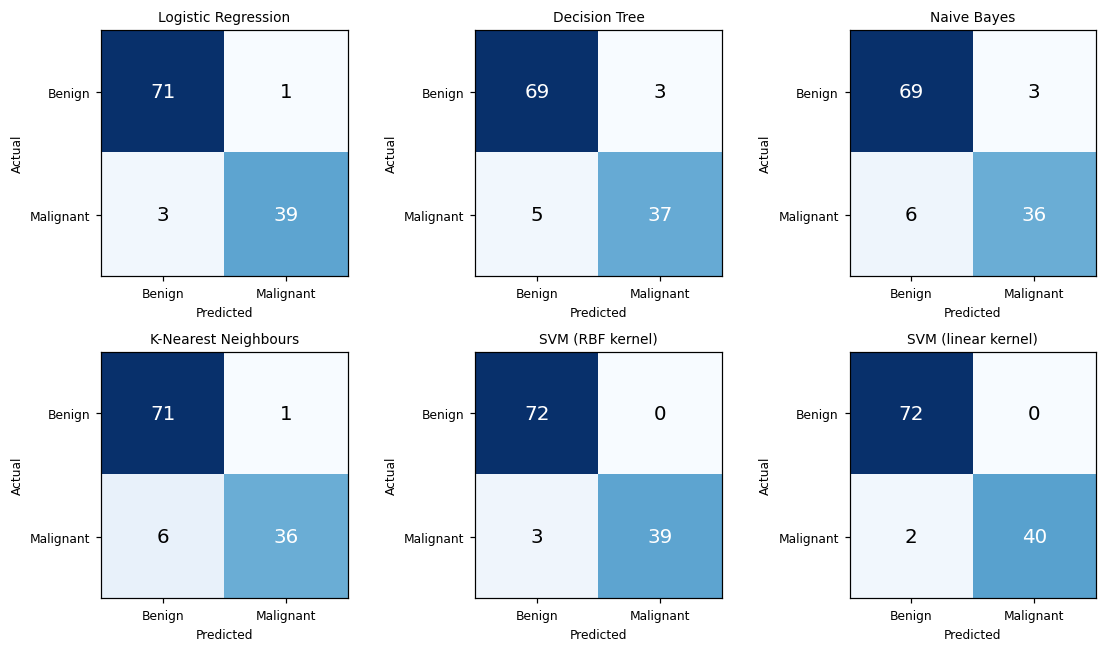

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(10.5, 6))
for a, (name, cm) in zip(ax.ravel(), cms.items()):
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a.text(j, i, cm[i, j], ha="center", va="center", fontsize=13, color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks([0, 1]); a.set_yticks([0, 1]); a.set_xticklabels(["Benign", "Malignant"], fontsize=8); a.set_yticklabels(["Benign", "Malignant"], fontsize=8)
    a.set_title(name, fontsize=9); a.set_xlabel("Predicted", fontsize=8); a.set_ylabel("Actual", fontsize=8)
plt.tight_layout()

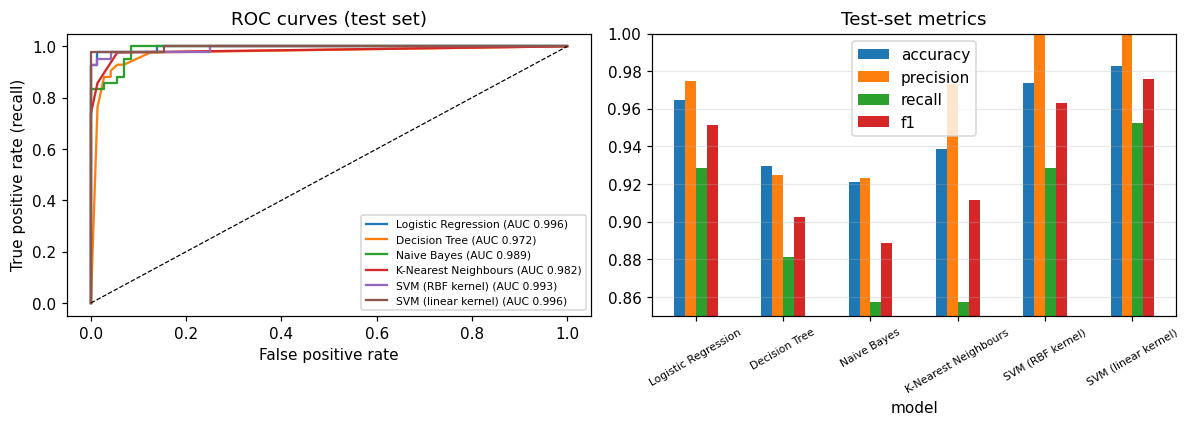

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p); ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate (recall)"); ax[0].set_title("ROC curves (test set)"); ax[0].legend(fontsize=7)
res[["accuracy", "precision", "recall", "f1"]].plot.bar(ax=ax[1], ylim=(0.85, 1.0)); ax[1].set_title("Test-set metrics"); ax[1].tick_params(axis="x", labelrotation=30, labelsize=7); ax[1].grid(alpha=.3, axis="y")
plt.tight_layout()

## 6. Stability check: repeated cross-validation on the whole data set
A single test split of 114 patients is small (one patient = 0.9% accuracy). The tuned models are therefore also evaluated with **5-fold CV repeated 3 times** (15 folds).

In [12]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RS)
rows = []
for name, gs in best.items():
    cvres = cross_validate(gs.best_estimator_, X, y, cv=rcv, scoring=["accuracy", "recall", "f1"])
    rows.append([name, cvres["test_accuracy"].mean(), cvres["test_accuracy"].std(), cvres["test_recall"].mean(), cvres["test_f1"].mean()])
stab = pd.DataFrame(rows, columns=["model", "acc_mean", "acc_sd", "recall_mean", "f1_mean"]).set_index("model").round(4)
stab.sort_values("acc_mean", ascending=False)

                      acc_mean  acc_sd  recall_mean  f1_mean
model                                                       
Logistic Regression     0.9760  0.0127       0.9512   0.9669
SVM (linear kernel)     0.9736  0.0124       0.9434   0.9635
SVM (RBF kernel)        0.9730  0.0118       0.9543   0.9634
K-Nearest Neighbours    0.9672  0.0130       0.9277   0.9543
Naive Bayes             0.9315  0.0176       0.8979   0.9069
Decision Tree           0.9314  0.0261       0.8948   0.9063

## 7. Part B: Regression (Linear Regression and RMSE) on the Diabetes dataset

In [13]:
dd = load_diabetes(as_frame=True)
Xd, yd = dd.data, dd.target
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.2, random_state=RS)
print("Instances:", Xd.shape[0], "| Features:", Xd.shape[1], "| target mean %.1f, sd %.1f" % (yd.mean(), yd.std()))
reg = {"Mean predictor (baseline)": None, "Linear Regression": LinearRegression(), "Ridge (alpha=1)": Ridge(alpha=1.0),
       "Decision Tree (depth 3)": DecisionTreeRegressor(max_depth=3, random_state=RS), "KNN (k=10)": Pipeline([("sc", StandardScaler()), ("m", KNeighborsRegressor(10))])}
rows = []
for name, m in reg.items():
    pred = np.full(len(yd_te), yd_tr.mean()) if m is None else m.fit(Xd_tr, yd_tr).predict(Xd_te)
    rows.append([name, np.sqrt(mean_squared_error(yd_te, pred)), mean_absolute_error(yd_te, pred), r2_score(yd_te, pred)])
regres = pd.DataFrame(rows, columns=["model", "RMSE", "MAE", "R2"]).set_index("model").round(3)
regres

Instances: 442 | Features: 10 | target mean 152.1, sd 77.1


                             RMSE     MAE     R2
model                                           
Mean predictor (baseline)  73.222  64.006 -0.012
Linear Regression          53.853  42.794  0.453
Ridge (alpha=1)            55.474  46.139  0.419
Decision Tree (depth 3)    59.605  48.097  0.329
KNN (k=10)                 56.288  45.111  0.402

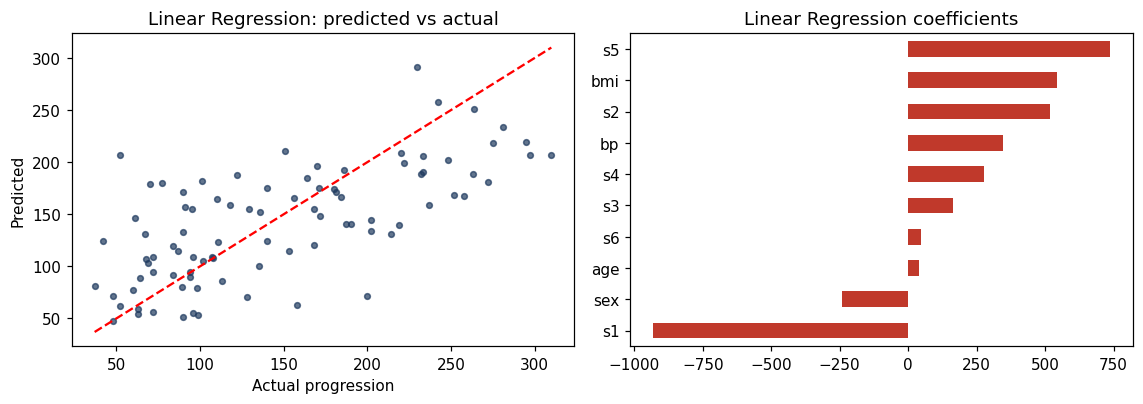

In [14]:
lr = reg["Linear Regression"]
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
pred = lr.predict(Xd_te)
ax[0].scatter(yd_te, pred, s=14, alpha=.7, color="#1F3A5F"); lim = [min(yd_te.min(), pred.min()), max(yd_te.max(), pred.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual progression"); ax[0].set_ylabel("Predicted"); ax[0].set_title("Linear Regression: predicted vs actual")
pd.Series(lr.coef_, index=Xd.columns).sort_values().plot.barh(ax=ax[1], color="#C0392B"); ax[1].set_title("Linear Regression coefficients")
plt.tight_layout()

In [15]:
best_name = res["f1"].idxmax()
SUMMARY = dict(n=int(X.shape[0]), p=int(X.shape[1]), n_mal=int(y.sum()), n_ben=int((1 - y).sum()), n_train=len(X_train), n_test=len(X_test),
               best_name=best_name, params={n: {k.replace("clf__", ""): (v if not isinstance(v, np.generic) else v.item()) for k, v in g.best_params_.items()} for n, g in best.items()},
               cv_f1={n: round(g.best_score_, 4) for n, g in best.items()},
               fn={n: int(cms[n][1, 0]) for n in cms}, fp={n: int(cms[n][0, 1]) for n in cms},
               top_features=list(scores.head(10).index), top_scores=[round(v, 1) for v in scores.head(10)])
print("Best model by test F1:", best_name)

Best model by test F1: SVM (linear kernel)


## 8. Observations and conclusions
* **Data:** 569 patients, 30 features, no missing values; 212 malignant (37%) and 357 benign — moderately imbalanced, so accuracy alone is not enough and precision/recall/F1 were used.
* **Preprocessing:** features have very different scales (area in hundreds, smoothness below 0.2), so scaling inside a Pipeline was essential for KNN, SVM and logistic regression and avoided leakage. Univariate selection shows that size and shape features (worst concave points, worst perimeter, worst radius, ...) are the most informative. However, using only the 10 best features gave 95.4% CV accuracy for logistic regression against 97.4% with all 30 features, so selection mainly helps simplicity and interpretation here, not accuracy.
* **Models:** on the single test split the best model was **SVM (linear kernel)** (Section 5). In repeated cross-validation (Section 6) logistic regression had the highest mean accuracy (97.6%) with the two SVMs and KNN within about one percentage point, which is smaller than the fold-to-fold standard deviation (about 1.2 points); these top models should therefore be regarded as practically equivalent. The decision tree and Naive Bayes were clearly weaker (about 93% accuracy): the tree is unstable, and the independence assumption of Naive Bayes does not hold for these strongly correlated features.
* **Errors that matter:** the number of malignant patients missed (false negatives) per model is in the confusion matrices; for a screening tool the decision threshold could be lowered to increase recall at the cost of more false alarms.
* **Reliability:** repeated cross-validation (Section 6) gives a more dependable ranking than the single 114-patient test set; differences of one or two patients between models are within noise.
* **Regression (Part B):** linear regression reduces RMSE compared with the mean-predictor baseline, but R² is only moderate, showing that the 10 baseline variables explain part of the variation in disease progression.
* **Limitations:** one dataset from one source; no external validation; the model is a learning exercise and **not** a clinical diagnostic tool.